In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
np.random.seed(42)

In [ ]:
mu_x = 0
mu_y = 0
sigma_x = 1
sigma_y = 1
rho = 0.8

In [ ]:
num_samples = 10000
burn_in = 1000

In [ ]:
x_samples = np.zeros(num_samples)
y_samples = np.zeros(num_samples)

In [ ]:
x_samples[0] = 0
y_samples[0] = 0

In [ ]:
for i in range(1, num_samples):

    mean_x_given_y = mu_x + rho * (sigma_x / sigma_y) * (y_samples[i-1] - mu_y)
    std_x_given_y = sigma_x * np.sqrt(1 - rho**2)

    x_samples[i] = np.random.normal(mean_x_given_y, std_x_given_y)

    mean_y_given_x = mu_y + rho * (sigma_y / sigma_x) * (x_samples[i] - mu_x)
    std_y_given_x = sigma_y * np.sqrt(1 - rho**2)

    y_samples[i] = np.random.normal(mean_y_given_x, std_y_given_x)

In [ ]:
x_final = x_samples[burn_in:]
y_final = y_samples[burn_in:]

In [ ]:
samples_df = pd.DataFrame({
    "X": x_final,
    "Y": y_final
})

print("First five generated samples:")
print(samples_df.head())

print("\nMean of X:", np.mean(x_final))
print("Mean of Y:", np.mean(y_final))
print("Correlation between X and Y:", np.corrcoef(x_final, y_final)[0, 1])

First five generated samples:
          X         Y
0  0.462502 -0.076940
1 -0.466659 -0.460039
2 -0.843483 -0.859563
3 -1.823819 -1.331079
4 -1.064140 -1.341565

Mean of X: 0.003140931923572693
Mean of Y: 0.003974930524317624
Correlation between X and Y: 0.7965271608314254


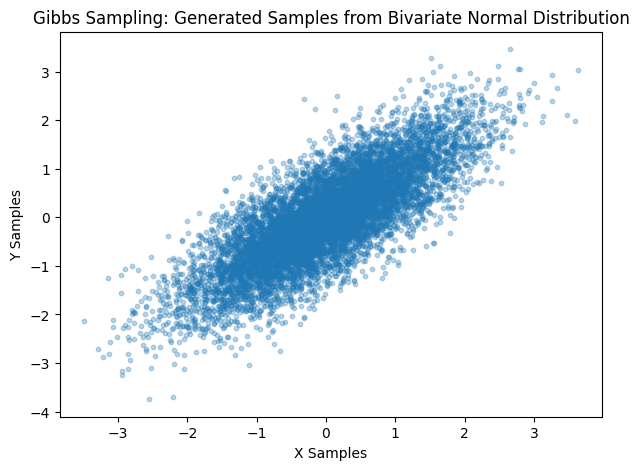

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(x_final, y_final, alpha=0.3, s=10)
plt.xlabel("X Samples")
plt.ylabel("Y Samples")
plt.title("Gibbs Sampling: Generated Samples from Bivariate Normal Distribution")
plt.show()

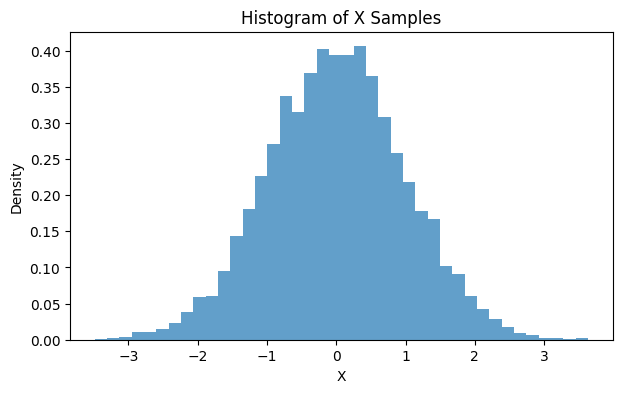

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(x_final, bins=40, density=True, alpha=0.7)
plt.xlabel("X")
plt.ylabel("Density")
plt.title("Histogram of X Samples")
plt.show()

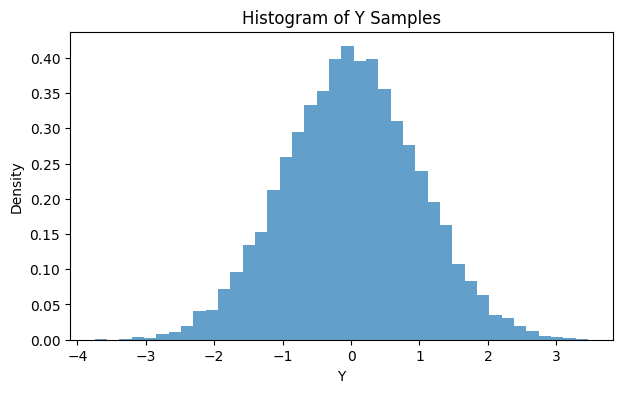

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(y_final, bins=40, density=True, alpha=0.7)
plt.xlabel("Y")
plt.ylabel("Density")
plt.title("Histogram of Y Samples")
plt.show()

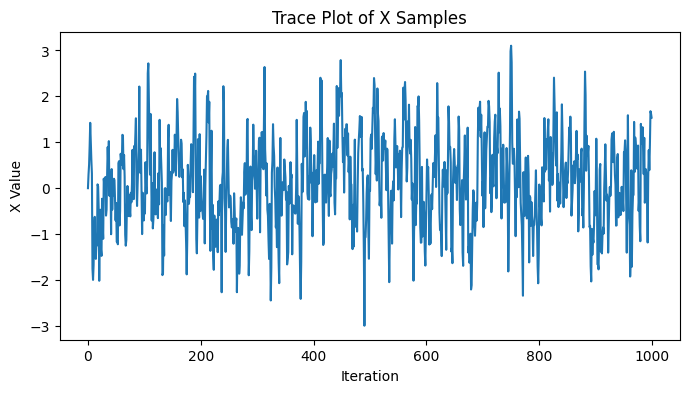

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(x_samples[:1000])
plt.xlabel("Iteration")
plt.ylabel("X Value")
plt.title("Trace Plot of X Samples")
plt.show()

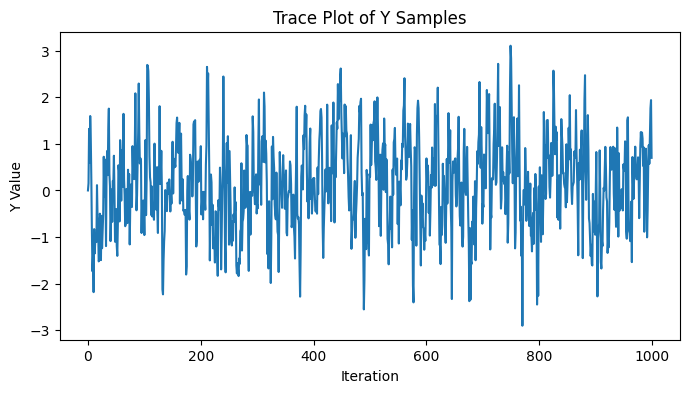

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(y_samples[:1000])
plt.xlabel("Iteration")
plt.ylabel("Y Value")
plt.title("Trace Plot of Y Samples")
plt.show()